# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'gracelh4'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

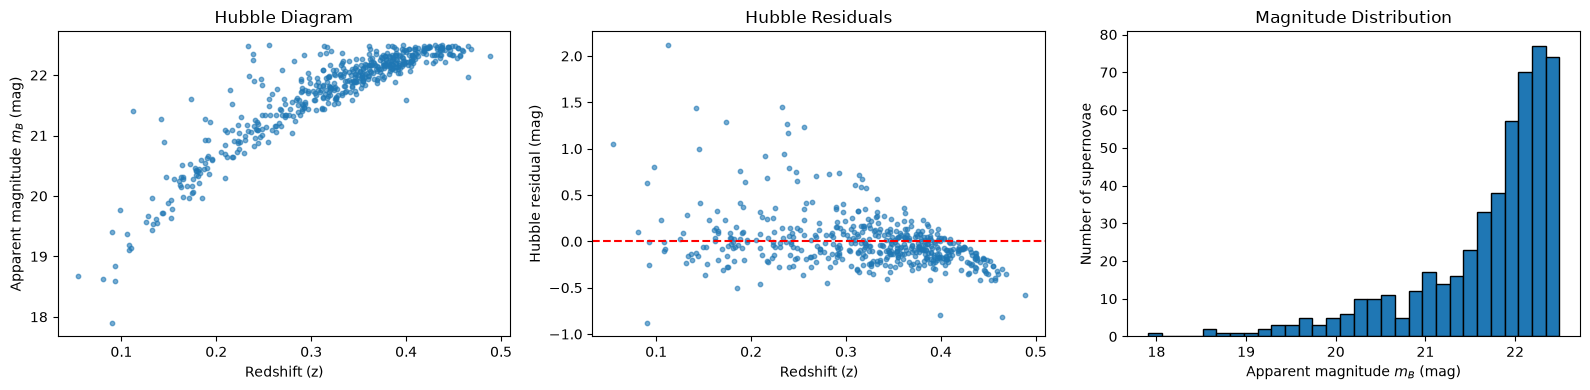

In [3]:
from astropy.cosmology import FlatLambdaCDM

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu = cosmo.distmod(z).value
residuals = m - (-19.30) - mu
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(z, m, s=10, alpha=0.6)
ax[0].set_xlabel("Redshift (z)")
ax[0].set_ylabel("Apparent magnitude $m_B$ (mag)")
ax[0].set_title("Hubble Diagram")

ax[1].scatter(z, residuals, s=10, alpha=0.6)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Redshift (z)")
ax[1].set_ylabel("Hubble residual (mag)")
ax[1].set_title("Hubble Residuals")

ax[2].hist(m, bins=30, edgecolor="black")
ax[2].set_xlabel("Apparent magnitude $m_B$ (mag)")
ax[2].set_ylabel("Number of supernovae")
ax[2].set_title("Magnitude Distribution")

plt.tight_layout()
plt.show()

The magnitude increases with redshift in the HUbble Diagram, and there is a concentration at high redshift and high apparent magnitude. 

The residuals are concentrated near the zero magnitude line, so these supernovae are probably close to the model's predictions.

There's a few outliers, so my simulator will need to account for them. 

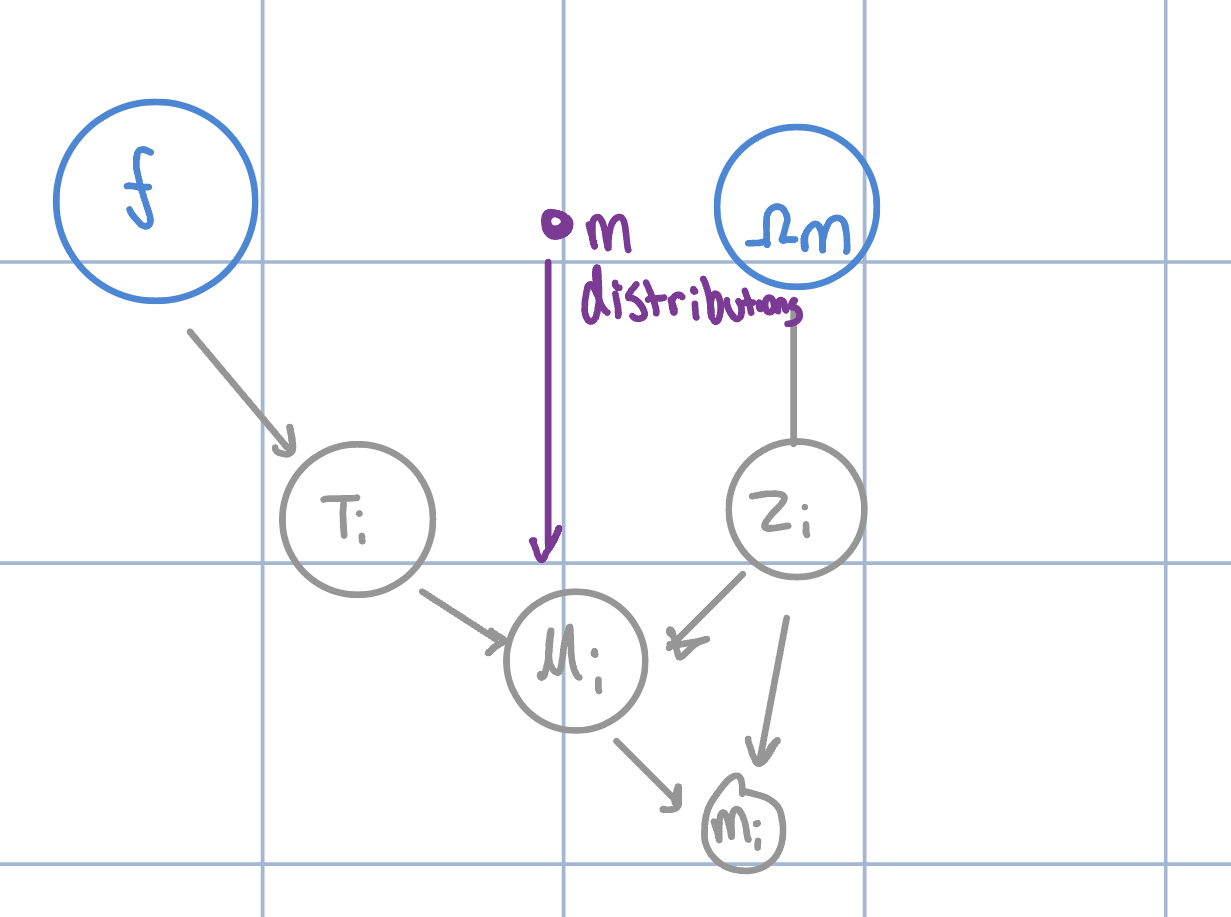

Astropy: [36.73459039 40.95546004 42.73899219]
Table: [36.73459038 40.95546004 42.73899219]
Difference: [-1.18107550e-08 -4.86297580e-09  1.75162995e-09]


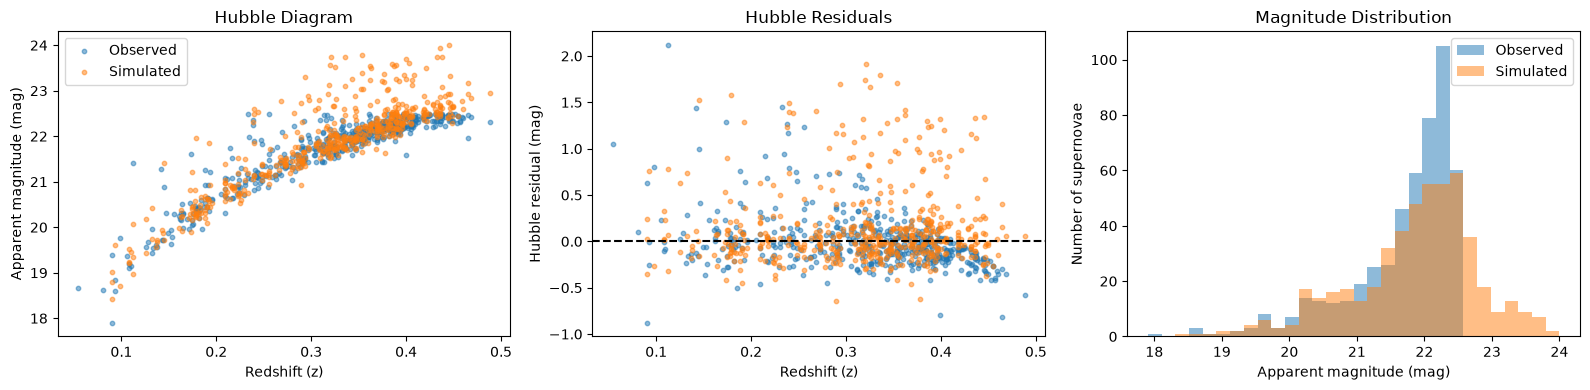

In [4]:
from scipy.integrate import cumulative_trapezoid

Om_grid = np.arange(0.05, 0.701, 0.005)
z_grid = np.linspace(0, 0.7, 1401)

E = np.sqrt( Om_grid[:, None] * (1 + z_grid[None, :])**3 + 1 - Om_grid[:, None])
integral = cumulative_trapezoid(1 / E, z_grid, axis=1, initial=0)
dL = (1 + z_grid[None, :]) * (299792.458 / 70) * integral
mu_grid = 5 * np.log10(np.maximum(dL, 1e-12)) + 25

def distance_modulus(z, Om):
    j = np.searchsorted(Om_grid, Om)
    j = np.clip(j, 1, len(Om_grid) - 1)
    weight = (Om - Om_grid[j-1]) / (Om_grid[j] - Om_grid[j-1])
    mu_low = np.interp(z, z_grid, mu_grid[j-1])
    mu_high = np.interp(z, z_grid, mu_grid[j])
    return (1 - weight) * mu_low + weight * mu_high

def simulate(Om, f, rng):
    N = 500

    z_sim = rng.choice(z, size=N, replace=True)

    impostor = rng.random(N) < f

    M_sim = rng.normal(-19.30, 0.12, N)
    M_sim[impostor] = rng.normal(-18.5, 0.5, impostor.sum())

    mu_sim = distance_modulus(z_sim, Om)

    m_sim = M_sim + mu_sim + rng.normal(0, 0.10, N)

    return z_sim, m_sim

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

z_test = np.array([0.05, 0.3, 0.6])
mu_astropy = cosmo.distmod(z_test).value
mu_table = distance_modulus(z_test, 0.3)

print("Astropy:", mu_astropy)
print("Table:", mu_table)
print("Difference:", mu_table - mu_astropy)

rng = np.random.default_rng(42)

Om_guess = 0.3
f_guess = 0.2

z_sim, m_sim = simulate(Om_guess, f_guess, rng)

res_obs = m - (-19.30) - distance_modulus(z, 0.3)
res_sim = m_sim - (-19.30) - distance_modulus(z_sim, 0.3)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(z, m, s=10, alpha=0.5, label="Observed")
ax[0].scatter(z_sim, m_sim, s=10, alpha=0.5, label="Simulated")
ax[0].set_xlabel("Redshift (z)")
ax[0].set_ylabel("Apparent magnitude (mag)")
ax[0].set_title("Hubble Diagram")
ax[0].legend()

ax[1].scatter(z, res_obs, s=10, alpha=0.5, label="Observed")
ax[1].scatter(z_sim, res_sim, s=10, alpha=0.5, label="Simulated")
ax[1].axhline(0, color="black", linestyle="--")
ax[1].set_xlabel("Redshift (z)")
ax[1].set_ylabel("Hubble residual (mag)")
ax[1].set_title("Hubble Residuals")

bins = np.linspace( min(m.min(), m_sim.min()), max(m.max(), m_sim.max()), 31)

ax[2].hist(m, bins=bins, alpha=0.5, label="Observed")
ax[2].hist(m_sim, bins=bins, alpha=0.5, label="Simulated")
ax[2].set_xlabel("Apparent magnitude (mag)")
ax[2].set_ylabel("Number of supernovae")
ax[2].set_title("Magnitude Distribution")
ax[2].legend()

plt.tight_layout()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

My simulator generates a fake dataset with 500 supernovae, assuming an omega value of 0.3 and an impostor fraction of 0.2. It assigns redshifts randomly. 

It then determines the type, absolute mag and calculates apparent mag, and plots it. 

The simulated data is close to the true data, but there more positive residuals. 

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [5]:
from scipy.optimize import minimize_scalar, brentq

sigma_tot = np.sqrt(0.12**2 + 0.10**2)

def chi2(Om):
    mu = distance_modulus(z, Om)
    residuals = m - (-19.30) - mu
    return np.sum((residuals / sigma_tot)**2)

result = minimize_scalar(chi2, bounds=(0.05, 0.7), method="bounded")

Om_best = result.x
chi2_min = result.fun

def delta_chi2(Om):
    return chi2(Om) - chi2_min - 1

Om_lower = brentq(delta_chi2, 0.05, Om_best)
Om_upper = brentq(delta_chi2, Om_best, 0.7)

sigma_Om = (Om_upper - Om_lower) / 2

print(f"Best-fit Omega_m = {Om_best:.4f}")
print(f"1-sigma uncertainty = {sigma_Om:.4f}")
print(f"Omega_m = {Om_best:.4f} +/- {sigma_Om:.4f}")
print(f"Minimum chi-squared = {chi2_min:.2f}")

Best-fit Omega_m = 0.3677
1-sigma uncertainty = 0.0141
Omega_m = 0.3677 +/- 0.0141
Minimum chi-squared = 1795.10


**ANSWER (the naive fit, then why the impostors push it the way they do):**

The impostors push the fitted omega m downward on the Hubble diagram, because they are much fainter than Type Ia supernovae. When we treat them like Type IA supernovae, the residuals make them appear further away, so they get pulled down. 

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

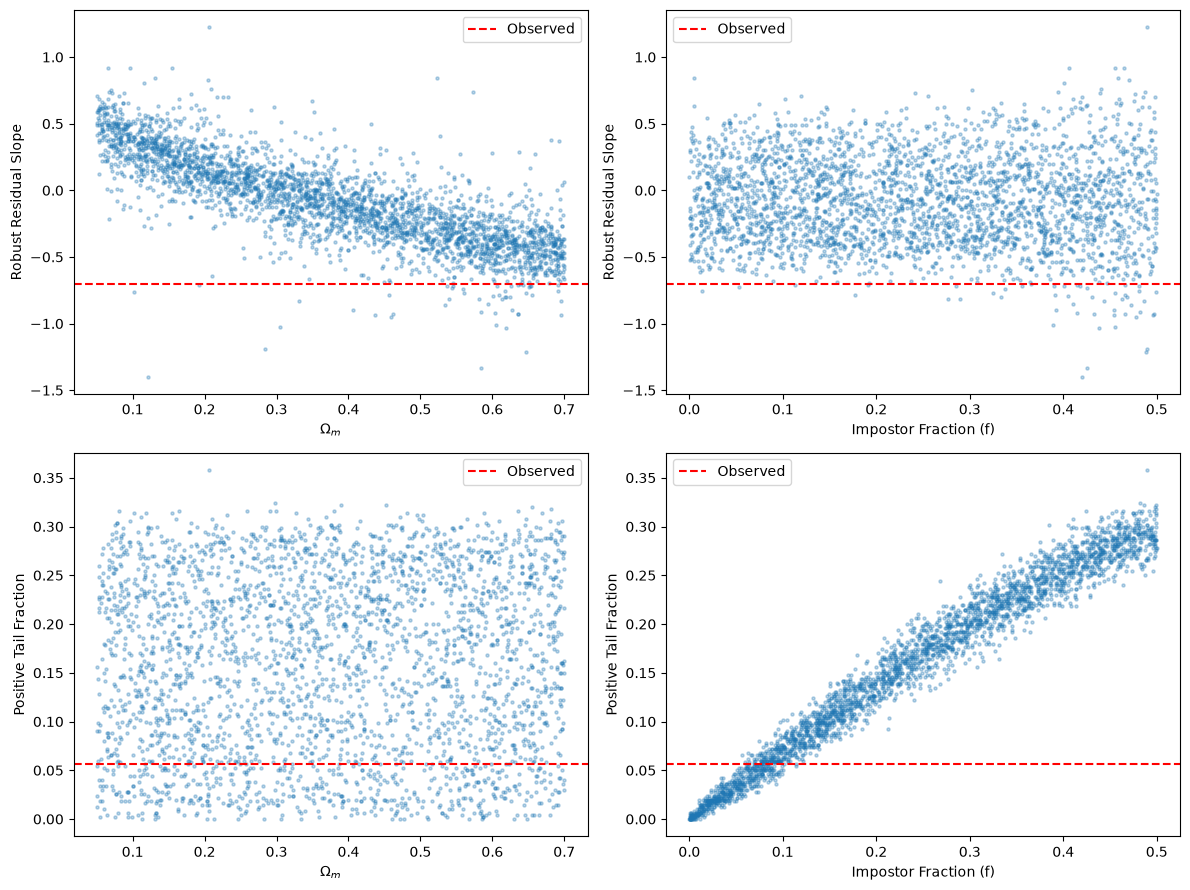

Observed robust residual slope: -0.7053121450021207
Observed positive tail fraction: 0.056
Fraction of simulated slopes below observed: 0.01633333333333333


In [15]:
import numpy as np
import matplotlib.pyplot as plt

def summaries(z_data, m_data):
    residuals = m_data + 19.30 - distance_modulus(z_data, 0.3)

    edges = np.quantile(z_data, np.linspace(0, 1, 6))
    bin_idx = np.searchsorted(edges[1:-1], z_data)

    z_medians = np.array([
        np.median(z_data[bin_idx == i]) for i in range(5)
    ])

    res_medians = np.array([
        np.median(residuals[bin_idx == i]) for i in range(5)
    ])

    slope = np.polyfit(z_medians, res_medians, 1)[0]

    centered = residuals - np.median(residuals)
    tail_fraction = np.mean(centered > 0.5)

    return np.array([slope, tail_fraction])

rng = np.random.default_rng(42)

N_sim = 3000

Om_samples = rng.uniform(0.05, 0.7, N_sim)
f_samples = rng.uniform(0, 0.5, N_sim)

sim_summaries = np.zeros((N_sim, 2))

for i in range(N_sim):
    z_sim, m_sim = simulate(Om_samples[i], f_samples[i], rng)
    sim_summaries[i] = summaries(z_sim, m_sim)

observed_summaries = summaries(z, m)

fig, ax = plt.subplots(2, 2, figsize=(12, 9))

names = ["Robust Residual Slope", "Positive Tail Fraction"]
parameters = [Om_samples, f_samples]
parameter_names = [r"$\Omega_m$", "Impostor Fraction (f)"]

for i in range(2):
    for j in range(2):
        ax[i, j].scatter(
            parameters[j],
            sim_summaries[:, i],
            s=5,
            alpha=0.3
        )

        ax[i, j].axhline(
            observed_summaries[i],
            color="red",
            linestyle="--",
            label="Observed"
        )

        ax[i, j].set_xlabel(parameter_names[j])
        ax[i, j].set_ylabel(names[i])
        ax[i, j].legend()

plt.tight_layout()
plt.show()

print("Observed robust residual slope:", observed_summaries[0])
print("Observed positive tail fraction:", observed_summaries[1])

print("Fraction of simulated slopes below observed:",
      np.mean(sim_summaries[:, 0] <= observed_summaries[0]))


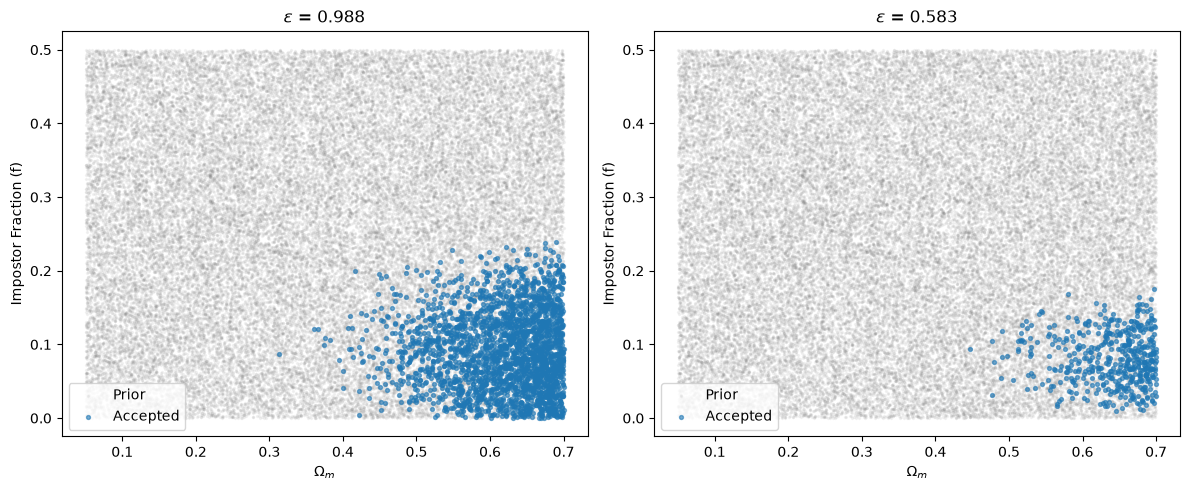

Large epsilon: 0.9877
Accepted draws: 2500
Acceptance rate: 5.00%

Small epsilon: 0.5834
Accepted draws: 500
Acceptance rate: 1.00%


In [16]:
rng = np.random.default_rng(42)

N_sim = 50000

Om_samples = rng.uniform(0.05, 0.7, N_sim)
f_samples = rng.uniform(0, 0.5, N_sim)

sim_summaries = np.zeros((N_sim, 2))

for i in range(N_sim):
    z_sim, m_sim = simulate(Om_samples[i], f_samples[i], rng)
    sim_summaries[i] = summaries(z_sim, m_sim)

observed_summaries = summaries(z, m)

scales = np.std(sim_summaries, axis=0)

distances = np.sqrt( np.sum( ((sim_summaries - observed_summaries) / scales)**2,  axis=1 ))

eps1 = np.quantile(distances, 0.05)
eps2 = np.quantile(distances, 0.01)

accepted1 = distances <= eps1
accepted2 = distances <= eps2

np.savez(
    "abc_simulations.npz",
    Om_samples=Om_samples,
    f_samples=f_samples,
    sim_summaries=sim_summaries,
    distances=distances,
    scales=scales,
    observed_summaries=observed_summaries,
    eps1=eps1,
    eps2=eps2)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for a, accepted, eps in zip( ax,  [accepted1, accepted2],  [eps1, eps2]):
    a.scatter(
        Om_samples,
        f_samples,
        s=2,
        alpha=0.08,
        color="gray",
        label="Prior"
    )

    a.scatter(
        Om_samples[accepted],
        f_samples[accepted],
        s=8,
        alpha=0.6,
        label="Accepted"
    )

    a.set_xlabel(r"$\Omega_m$")
    a.set_ylabel("Impostor Fraction (f)")
    a.set_title(rf"$\epsilon$ = {eps:.3f}")
    a.legend()

plt.tight_layout()
plt.show()

print(f"Large epsilon: {eps1:.4f}")
print(f"Accepted draws: {accepted1.sum()}")
print(f"Acceptance rate: {accepted1.mean():.2%}")

print(f"\nSmall epsilon: {eps2:.4f}")
print(f"Accepted draws: {accepted2.sum()}")
print(f"Acceptance rate: {accepted2.mean():.2%}")


ABC Posterior Results
---------------------
Omega_m median: 0.6532
Omega_m 95% interval: [0.5158, 0.6978]

f median: 0.0786
f 95% interval: [0.0199, 0.1470]

Comparison with Part 2
----------------------
Naive Omega_m: 0.3677 +/- 0.0141
ABC Omega_m: 0.6532
Difference: 0.2855


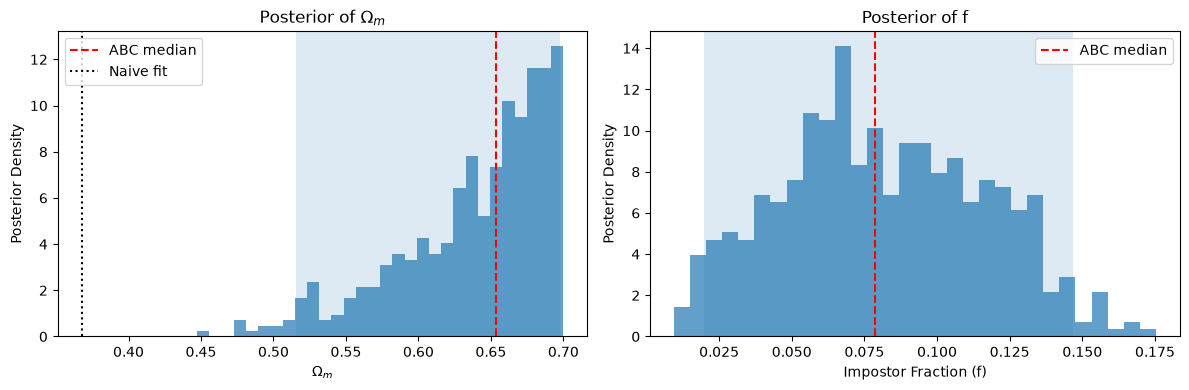

In [17]:
data = np.load("abc_simulations.npz")

Om_samples = data["Om_samples"]
f_samples = data["f_samples"]
distances = data["distances"]
eps2 = float(data["eps2"])

accepted = distances <= eps2

Om_post = Om_samples[accepted]
f_post = f_samples[accepted]

Om_median = np.median(Om_post)
Om_lower, Om_upper = np.percentile(Om_post, [2.5, 97.5])

f_median = np.median(f_post)
f_lower, f_upper = np.percentile(f_post, [2.5, 97.5])

print("ABC Posterior Results")
print("---------------------")

print(f"Omega_m median: {Om_median:.4f}")
print(f"Omega_m 95% interval: [{Om_lower:.4f}, {Om_upper:.4f}]")

print(f"\nf median: {f_median:.4f}")
print(f"f 95% interval: [{f_lower:.4f}, {f_upper:.4f}]")

print("\nComparison with Part 2")
print("----------------------")

print(f"Naive Omega_m: {Om_best:.4f} +/- {sigma_Om:.4f}")
print(f"ABC Omega_m: {Om_median:.4f}")
print(f"Difference: {Om_median - Om_best:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(Om_post, bins=30, density=True, alpha=0.7)
ax[0].axvline(Om_median, color="red", linestyle="--", label="ABC median")
ax[0].axvline(Om_best, color="black", linestyle=":", label="Naive fit")
ax[0].axvspan(Om_lower, Om_upper, alpha=0.15)
ax[0].set_xlabel(r"$\Omega_m$")
ax[0].set_ylabel("Posterior Density")
ax[0].set_title(r"Posterior of $\Omega_m$")
ax[0].legend()

ax[1].hist(f_post, bins=30, density=True, alpha=0.7)
ax[1].axvline(f_median, color="red", linestyle="--", label="ABC median")
ax[1].axvspan(f_lower, f_upper, alpha=0.15)
ax[1].set_xlabel("Impostor Fraction (f)")
ax[1].set_ylabel("Posterior Density")
ax[1].set_title("Posterior of f")
ax[1].legend()

plt.tight_layout()
plt.show()


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

1) I tracked the matter density and the impostor fraction. The matter density influences the luminosity distance-redshift relationship, which influences the residual slopes. The impostors are fainter, which will produce larger residuals.

2) I used the standardized Euclidean distance to measure the distances between them.

Two tolerances were tested, the larger one accepted 2,500 simulations while the smaller accepted 500. The smaller kept simulatons close to summary stats. That tolerance was 0.5834. 

3) I chose the smaller tolerance because it was closest to the observed data. My estimate is higher than the chi-squred estimate, but my estimate is concentrated near the upper prior boundary, indicating that the matter density may be influenced by the prior limit. 

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

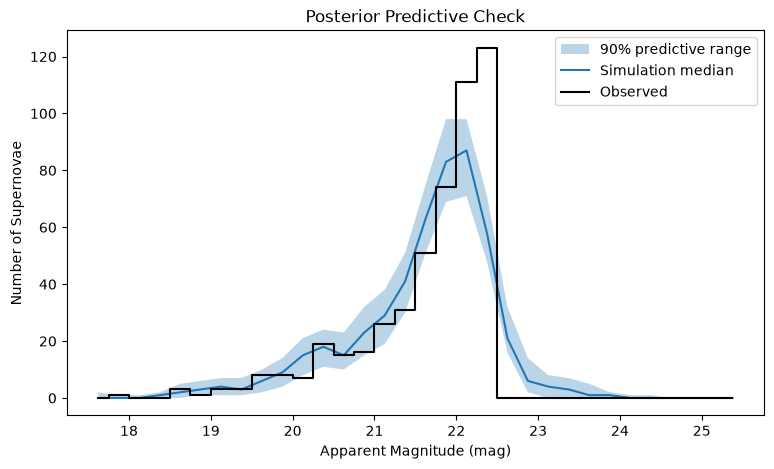

Fraction of histogram bins inside predictive range: 0.84375


In [18]:

data = np.load("abc_simulations.npz")

Om_samples = data["Om_samples"]
f_samples = data["f_samples"]
distances = data["distances"]
eps2 = float(data["eps2"])

accepted_idx = np.where(distances <= eps2)[0]

rng = np.random.default_rng(42)
chosen = rng.choice(accepted_idx, size=100, replace=False)

bins = np.linspace(17.5, 25.5, 33)
sim_histograms = np.zeros((100, len(bins) - 1))

for i, idx in enumerate(chosen):
    z_sim, m_sim = simulate(Om_samples[idx], f_samples[idx], rng)
    sim_histograms[i], _ = np.histogram(m_sim, bins=bins)

obs_hist, _ = np.histogram(m, bins=bins)

lower = np.percentile(sim_histograms, 5, axis=0)
median = np.median(sim_histograms, axis=0)
upper = np.percentile(sim_histograms, 95, axis=0)

centers = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(9, 5))
plt.fill_between(centers, lower, upper, alpha=0.3, label="90% predictive range")
plt.plot(centers, median, label="Simulation median")
plt.step(centers, obs_hist, where="mid", label="Observed", color="black")

plt.xlabel("Apparent Magnitude (mag)")
plt.ylabel("Number of Supernovae")
plt.title("Posterior Predictive Check")
plt.legend()
plt.show()

inside = (obs_hist >= lower) & (obs_hist <= upper)

print("Fraction of histogram bins inside predictive range:", inside.mean())


# Yes, it mostly agrees with the observed data.

In [19]:

data = np.load("abc_simulations.npz")

Om_samples = data["Om_samples"]
f_samples = data["f_samples"]
sim_summaries = data["sim_summaries"]
scales = data["scales"]
eps2 = float(data["eps2"])

rng = np.random.default_rng(123)

N_test = 20
test_idx = rng.choice(len(Om_samples), size=N_test, replace=False)

Om_covered = []
f_covered = []
accepted_counts = []

for idx in test_idx:
    fake_observed = sim_summaries[idx]

    distances_test = np.sqrt(
        np.sum(
            ((sim_summaries - fake_observed) / scales)**2,
            axis=1
        )
    )

    accepted = distances_test <= eps2
    accepted[idx] = False

    accepted_counts.append(accepted.sum())

    if accepted.sum() < 20:
        Om_covered.append(np.nan)
        f_covered.append(np.nan)
        continue

    Om_post = Om_samples[accepted]
    f_post = f_samples[accepted]

    Om_low, Om_high = np.percentile(Om_post, [2.5, 97.5])
    f_low, f_high = np.percentile(f_post, [2.5, 97.5])

    Om_covered.append(Om_low <= Om_samples[idx] <= Om_high)
    f_covered.append(f_low <= f_samples[idx] <= f_high)

Om_covered = np.array(Om_covered, dtype=float)
f_covered = np.array(f_covered, dtype=float)

print("Omega_m coverage:", np.nanmean(Om_covered))
print("f coverage:", np.nanmean(f_covered))
print("Omega_m covered:", int(np.nansum(Om_covered)), "of", np.isfinite(Om_covered).sum())
print("f covered:", int(np.nansum(f_covered)), "of", np.isfinite(f_covered).sum())
print("Accepted counts:", accepted_counts)
print("Tests with insufficient draws:", np.sum(~np.isfinite(Om_covered)))


Omega_m coverage: 0.95
f coverage: 1.0
Omega_m covered: 19 of 20
f covered: 20 of 20
Accepted counts: [np.int64(5888), np.int64(4371), np.int64(6122), np.int64(1455), np.int64(6094), np.int64(5015), np.int64(4255), np.int64(1902), np.int64(5330), np.int64(3974), np.int64(5239), np.int64(5404), np.int64(4204), np.int64(1921), np.int64(4331), np.int64(4956), np.int64(5582), np.int64(5891), np.int64(5453), np.int64(6146)]
Tests with insufficient draws: 0


**ANSWER (the check, the coverage, and the assumption):**

My simulator does not account for magnitude dependent detection limits, which influences the population collected in the data. This biases the simulator upwards. 

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I used ChatGPT

Part 1:

I requested the boilerplate code for each coding question here. In addition, I discussed the diagram I drew with Chat, to make sure I understood the flow of it. 

Part 2:

Requested the code for this section, and discussed the results with Chat. 

Part 3:

Requested code for this section. Requested debugging code for this section once I hit errors, specifically in my slopes for the residuals. 

Requested assistance in interpreting results. 

Part 4: 

Requested the code for this section, discussed results with Chat. 

I was confused on the last question in 4, so I talked to Chat about it. 



**REFLECTION:**

For part 3, I had an issue were the residual slope was too sensitive to outliers. Had I not checked it, it would have thrown off the entirety of step 3. 



**VERIFICATION PLAN:**

I tested to see if my credible intervals contained the true parameters with the 20 simulated datasets. I got 19/20, which is above the failuare of less than 95%.

I also found that 84.4% of my histogram bins fell in 90% of the predictive range when I generated datasets with ABC parameters. Failure would have been a significantly lower percentage of histogram bins. 